In [4]:
import numpy as np
import matplotlib.pyplot as plt
from plotly.subplots import make_subplots
import pandas as pd
import glob 
import os
import pickle


import scipy.signal as signal
import scipy.fft as fft
import scipy.stats as stats

import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import plotly.express as px
import pandas as pd
import glob 
import pywt #PyWavelets package
import matplotlib.colors as colors




from data_process import select_df,fac_decompose_dB,read_and_process_data

# one event

In [ ]:
start_time=pd.to_datetime('2010-12-21 02:50:00')
end_time=pd.to_datetime('2010-12-21 03:20:00')
df=select_df(start_time,end_time)
df=read_and_process_data(start_time,end_time)

In [18]:
df["BTOTAL"].mean()

np.float64(185.76593666666668)

In [19]:
# cyclotron frequency of H2O+ ion in Saturn's magnetosphere: qB/(2 pi m)
cyclotron_freq=  (df["BTOTAL"].mean()*1e-9 * 1.6e-19) /(2*np.pi* 18*1.66e-27 )

<>:49: SyntaxWarning: invalid escape sequence '\O'
<>:49: SyntaxWarning: invalid escape sequence '\O'
/var/folders/v_/4hys7cx12_q5gs6s1c9gqrvm0000gn/T/ipykernel_76991/49124477.py:49: SyntaxWarning: invalid escape sequence '\O'
  ax.axvspan(0.5*cyclotron_freq, 2*cyclotron_freq, color='C2', alpha=0.1, label='0.5-2 $\Omega_{H_2O^+}$ range')
/var/folders/v_/4hys7cx12_q5gs6s1c9gqrvm0000gn/T/ipykernel_76991/49124477.py:27: RuntimeWarning: divide by zero encountered in divide
  Power_parallel=np.abs(F_parallel)**2/(N*freqs_parallel)
/var/folders/v_/4hys7cx12_q5gs6s1c9gqrvm0000gn/T/ipykernel_76991/49124477.py:28: RuntimeWarning: divide by zero encountered in divide
  Power_perp=(np.abs(F_perpendicular_1)**2+np.abs(F_perpendicular_2)**2)/(N*freqs_perpendicular)


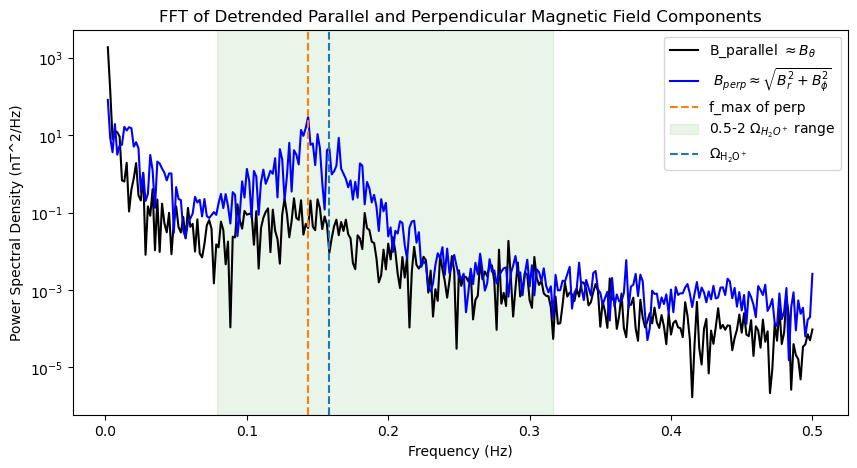

In [42]:
# do the same to dB_parallel and dB_perpendicular components
# col=['dB_parallel','dB_perpendicular']
# F_list=[]
# for c in col:
#     fn=df[c].values
#     N=len(fn)
#     T=1/df['TIME'].diff().dt.total_seconds().mean() # sampling interval in seconds
#     F1 = fft.rfft(fn)
#     freqs = fft.rfftfreq(N,d=T)
#     F_list.append((freqs,F1))  

fn=df['dB_parallel'].values
N=len(fn)
T=1/df['TIME'].diff().dt.total_seconds().mean() # sampling interval in seconds
F_parallel = fft.rfft(fn)
freqs_parallel = fft.rfftfreq(N,d=T)

fn=df['dB_perpendicular_1'].values
F_perpendicular_1 = fft.rfft(fn)
freqs_perpendicular = fft.rfftfreq(N,d=T)   

fn=df['dB_perpendicular_2'].values
F_perpendicular_2 = fft.rfft(fn)
freqs_perpendicular = fft.rfftfreq(N,d=T)  


Power_parallel=np.abs(F_parallel)**2/(N*freqs_parallel)
Power_perp=(np.abs(F_perpendicular_1)**2+np.abs(F_perpendicular_2)**2)/(N*freqs_perpendicular)
    
    
freq=freqs_parallel[1]-freqs_parallel[0]


color=['black','blue']

fig,ax=plt.subplots(figsize=(10,5))
ax.plot(freqs_parallel,Power_parallel,label=r'B_parallel $ \approx B_{\theta}$',color=color[0])
ax.plot(freqs_perpendicular,Power_perp,label=r' $B_{perp} \approx \sqrt{ B_{r}^2+ B_{\phi}^2}$',color=color[1])

    
# identify maximum peak within a certain frequency range (e.g., 1/2 to 2 times the cyclotron frequency)
range_mask = (freqs_parallel > 0.5*cyclotron_freq) & (freqs_parallel < 2*cyclotron_freq)
idx=np.argmax(Power_perp[range_mask])
max_peak_freq = freqs_perpendicular[range_mask][idx]
ax.axvline(max_peak_freq,color='C1',linestyle='--',label=f'f_max of perp')  


#plot the shaded region corresponding to the frequency range of interest
ax.axvspan(0.5*cyclotron_freq, 2*cyclotron_freq, color='C2', alpha=0.1, label='0.5-2 $\Omega_{H_2O^+}$ range')


#plot a vertical line at the cyclotron frequency
ax.axvline(cyclotron_freq,color='C0',linestyle='--',label=r'$\Omega_{\mathrm{H_2O^+}}$')    
ax.set_xlabel('Frequency (Hz)')
ax.set_title('FFT of Detrended Parallel and Perpendicular Magnetic Field Components')
# ax.set_xscale('log')
# ax.set_xlim(1e-2,1e0) # Limit x-axis to Nyquist frequency
ax.set_ylabel('Power Spectral Density (nT^2/Hz)')
ax.set_yscale('log')
# ax.set_ylim(None,5e-2)
ax.legend()
plt.show()


## make it batch operation

In [ ]:
#detrend is 1200s. so the start time is 10min eariler than intended, and end time is 10min later.

In [47]:
fn = df['dB_parallel'].values
N = len(fn)

dt = df['TIME'].diff().dt.total_seconds().mean()  # sampling interval in seconds

F_parallel = fft.rfft(fn)
freqs_parallel = fft.rfftfreq(N, d=dt)

fn = df['dB_perpendicular_1'].values
F_perpendicular_1 = fft.rfft(fn)

fn = df['dB_perpendicular_2'].values
F_perpendicular_2 = fft.rfft(fn)

freqs_perpendicular = fft.rfftfreq(N, d=dt)

# Avoid division by zero at f = 0
Power_parallel = np.zeros_like(freqs_parallel)
Power_perp = np.zeros_like(freqs_perpendicular)

nonzero_parallel = freqs_parallel > 0
nonzero_perp = freqs_perpendicular > 0

Power_parallel[nonzero_parallel] = (
    np.abs(F_parallel[nonzero_parallel])**2
    / (N * freqs_parallel[nonzero_parallel])
)

Power_perp[nonzero_perp] = (
    np.abs(F_perpendicular_1[nonzero_perp])**2
    + np.abs(F_perpendicular_2[nonzero_perp])**2
) / (N * freqs_perpendicular[nonzero_perp])


# Frequency range: 0.5 to 2 times cyclotron frequency
range_mask = (
    (freqs_perpendicular > 0.5 * cyclotron_freq)
    & (freqs_perpendicular < 2.0 * cyclotron_freq)
)

freq_range = freqs_perpendicular[range_mask]
power_range = Power_perp[range_mask]

idx = np.argmax(power_range)
max_peak_freq = freq_range[idx]

ax.axvline(
    max_peak_freq,
    color='C1',
    linestyle='--',
    label='f_max of perp'
)

# Judge whether maximum is at boundary
is_lower_boundary = idx == 0
is_upper_boundary = idx == len(power_range) - 1
is_boundary = is_lower_boundary or is_upper_boundary

if not is_boundary:
    is_ICW = True
    print("Peak is not at boundary: possible ICW")
else:
    is_ICW = False
    print("Peak is at boundary: not reliable ICW identification")

print(f"Peak frequency = {max_peak_freq:.4g} Hz")
print(f"Cyclotron frequency = {cyclotron_freq:.4g} Hz")
print(f"Peak / cyclotron = {max_peak_freq / cyclotron_freq:.3f}")

Peak is not at boundary: possible ICW
Peak frequency = 0.1433 Hz
Cyclotron frequency = 0.1583 Hz
Peak / cyclotron = 0.905


In [48]:
## load in the location data of cassini from "cassini_j2000_saturn_centered_2004_2017_60s.pkl"
with open("cassini_j2000_saturn_centered_2004_2017_60s.pkl", "rb") as f:
    cassini_location = pickle.load(f)

In [49]:
cassini_location.head()

,utc,et,x_km,y_km,z_km,vx_km_s,vy_km_s,vz_km_s,r_km,speed_km_s,x_Rs,y_Rs,z_Rs,r_Rs
0,2004-01-01 00:00:00+00:00,1.261873e+08,-6.961639e+07,-5.068772e+07,-1.502691e+07,4.213407,3.071488,0.91844,8.741564e+07,5.294371,-1155.113603,-841.038679,-249.334826,1450.448673
1,2004-01-01 00:01:00+00:00,1.261873e+08,-6.961613e+07,-5.068753e+07,-1.502686e+07,4.213407,3.071488,0.91844,8.741532e+07,5.294371,-1155.109409,-841.035622,-249.333911,1450.443402
2,2004-01-01 00:02:00+00:00,1.261874e+08,-6.961588e+07,-5.068735e+07,-1.502680e+07,4.213407,3.071488,0.91844,8.741501e+07,5.294372,-1155.105214,-841.032564,-249.332997,1450.438131
3,2004-01-01 00:03:00+00:00,1.261874e+08,-6.961563e+07,-5.068717e+07,-1.502675e+07,4.213407,3.071488,0.91844,8.741469e+07,5.294372,-1155.101019,-841.029506,-249.332082,1450.432860
4,2004-01-01 00:04:00+00:00,1.261875e+08,-6.961538e+07,-5.068698e+07,-1.502669e+07,4.213408,3.071488,0.91844,8.741437e+07,5.294372,-1155.096825,-841.026448,-249.331168,1450.427589


In [61]:

start_time=pd.to_datetime('2010-12-21 02:50:00')
end_time=pd.to_datetime('2010-12-21 03:20:00')
df=select_df(start_time,end_time)
df=read_and_process_data(start_time,end_time)

In [62]:
check_ICW(df)

True

In [56]:
def check_ICW(df):
    required_cols = [
        'TIME',
        'dB_parallel',
        'dB_perpendicular_1',
        'dB_perpendicular_2'
    ]

    # Missing columns
    for col in required_cols:
        if col not in df.columns:
            return False

    # Empty dataframe
    if df is None or len(df) < 2:
        return False

    # Remove NaNs/Infs
    df = df[required_cols].replace([np.inf, -np.inf], np.nan).dropna()

    if len(df) < 2:
        return False

    fn_parallel = df['dB_parallel'].values
    fn_perp1 = df['dB_perpendicular_1'].values
    fn_perp2 = df['dB_perpendicular_2'].values

    N = len(fn_parallel)

    if N < 2:
        return False

    dt = df['TIME'].diff().dt.total_seconds().mean()

    if not np.isfinite(dt) or dt <= 0:
        return False

    # FFT
    F_parallel = fft.rfft(fn_parallel)
    F_perpendicular_1 = fft.rfft(fn_perp1)
    F_perpendicular_2 = fft.rfft(fn_perp2)

    freqs_parallel = fft.rfftfreq(N, d=dt)
    freqs_perpendicular = fft.rfftfreq(N, d=dt)

    Power_parallel = np.zeros_like(freqs_parallel)
    Power_perp = np.zeros_like(freqs_perpendicular)

    nonzero_parallel = freqs_parallel > 0
    nonzero_perp = freqs_perpendicular > 0

    Power_parallel[nonzero_parallel] = (
        np.abs(F_parallel[nonzero_parallel])**2
        / (N * freqs_parallel[nonzero_parallel])
    )

    Power_perp[nonzero_perp] = (
        np.abs(F_perpendicular_1[nonzero_perp])**2
        + np.abs(F_perpendicular_2[nonzero_perp])**2
    ) / (N * freqs_perpendicular[nonzero_perp])

    range_mask = (
        (freqs_perpendicular > 0.5 * cyclotron_freq)
        & (freqs_perpendicular < 2.0 * cyclotron_freq)
    )

    freq_range = freqs_perpendicular[range_mask]
    power_range = Power_perp[range_mask]

    # No frequency bins in target range
    if len(power_range) == 0:
        return False

    # All bad powers
    if not np.any(np.isfinite(power_range)):
        return False

    idx = np.argmax(power_range)
    max_peak_freq = freq_range[idx]

    is_lower_boundary = idx == 0
    is_upper_boundary = idx == len(power_range) - 1
    is_boundary = is_lower_boundary or is_upper_boundary

    if not is_boundary:
        return True
    else:
        return False

In [64]:
start_time=pd.to_datetime('2010-12-21 00:50:00')
end_time=pd.to_datetime('2010-12-21 04:20:00')

# construct a for loop to check each 10-min interval within the time range
# construct a list or array of time and each time and whether it is ICW or not
time_intervals = []
is_ICW_list = []
length=int((end_time - start_time).total_seconds() // 600)  # number of 10-min intervals
for i in range(length):
    interval_start = start_time + pd.Timedelta(minutes=10*i)
    interval_end = interval_start + pd.Timedelta(minutes=30)
    df_interval = select_df(interval_start, interval_end)
    df_interval = read_and_process_data(interval_start, interval_end)
    is_ICW = check_ICW(df_interval)
    time_intervals.append(interval_start)
    is_ICW_list.append(is_ICW)



In [65]:
is_ICW_list

[True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True]

In [66]:
start_time=pd.to_datetime('2010-12-25 00:50:00')
end_time=pd.to_datetime('2010-12-26 04:20:00')

# construct a for loop to check each 10-min interval within the time range
# construct a list or array of time and each time and whether it is ICW or not
time_intervals = []
is_ICW_list = []
length=int((end_time - start_time).total_seconds() // 600)  # number of 10-min intervals
for i in range(length):
    interval_start = start_time + pd.Timedelta(minutes=10*i)
    interval_end = interval_start + pd.Timedelta(minutes=30)
    df_interval = select_df(interval_start, interval_end)
    df_interval = read_and_process_data(interval_start, interval_end)
    is_ICW = check_ICW(df_interval)
    time_intervals.append(interval_start)
    is_ICW_list.append(is_ICW)

In [80]:
is_ICW_list

[True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 False,
 True,
 True,
 False,
 True,
 False,
 True,
 False,
 False,
 False,
 True,
 True,
 True,
 False,
 True,
 True,
 True,
 True,
 True,
 False,
 True,
 True,
 True,
 False,
 True,
 False,
 True,
 True,
 True,
 True,
 False,
 False,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 False,
 False,
 False,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 False,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 False,
 True,
 False,
 True,
 True,
 True,
 F

In [68]:
start_time=pd.to_datetime('2010-12-21 02:50:00')
end_time=pd.to_datetime('2010-12-26 03:20:00')

df=select_df(start_time,end_time)
df=read_and_process_data(start_time,end_time)


In [69]:
df

,TIME,BR,BTHETA,BPHI,BTOTAL,NPTS,B0_R,B0_THETA,B0_PHI,B0_TOTAL,...,dB_THETA,dB_PHI,dB_TOTAL,b_hat_R,b_hat_THETA,b_hat_PHI,dB_parallel,dB_perpendicular,dB_perpendicular_1,dB_perpendicular_2
0,2010-12-21 03:00:00.500,-3.981,190.717,-0.115,190.758,16,-4.133346,190.659878,-0.175117,190.704757,...,0.057122,0.060117,0.173454,-0.021674,0.999765,-0.000918,0.053751,0.164915,0.153547,-0.060169
1,2010-12-21 03:00:01.500,-4.109,190.753,0.013,190.798,16,-4.132668,190.643682,-0.175085,190.688550,...,0.109318,0.188085,0.218830,-0.021672,0.999765,-0.000918,0.108606,0.189977,0.026027,-0.188185
2,2010-12-21 03:00:02.500,-4.251,190.756,-0.064,190.804,16,-4.132125,190.627467,-0.174842,190.672326,...,0.128533,0.110842,0.207215,-0.021671,0.999765,-0.000917,0.130978,0.160570,-0.116064,-0.110960
3,2010-12-21 03:00:03.500,-4.201,190.706,-0.186,190.752,16,-4.131766,190.611191,-0.174665,190.656047,...,0.094809,-0.011335,0.117943,-0.021671,0.999765,-0.000916,0.096298,0.068098,-0.067163,0.011248
4,2010-12-21 03:00:04.500,-4.050,190.651,-0.235,190.695,16,-4.131389,190.594957,-0.174733,190.639809,...,0.056043,-0.060267,0.115746,-0.021671,0.999765,-0.000917,0.054321,0.102207,0.082586,0.060215
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
432221,2010-12-26 03:09:55.500,0.044,1.749,0.088,1.752,8,0.365968,1.709684,0.181725,1.757833,...,0.039316,-0.093725,0.337629,0.208192,0.972609,0.103380,-0.038482,0.335429,-0.320989,0.097356
432222,2010-12-26 03:09:56.500,0.097,1.743,0.088,1.748,8,0.366185,1.709611,0.181781,1.757813,...,0.033389,-0.093781,0.287002,0.208319,0.972579,0.103413,-0.033301,0.285064,-0.268130,0.096785
432223,2010-12-26 03:09:57.500,0.155,1.730,0.090,1.739,8,0.366430,1.709507,0.181853,1.757770,...,0.020493,-0.091853,0.231430,0.208463,0.972543,0.103457,-0.033648,0.228971,-0.209008,0.093506
432224,2010-12-26 03:09:58.500,0.200,1.737,0.093,1.752,8,0.366691,1.709383,0.181918,1.757711,...,0.027617,-0.088918,0.190932,0.208618,0.972505,0.103497,-0.017120,0.190163,-0.166789,0.091342


<Axes: >

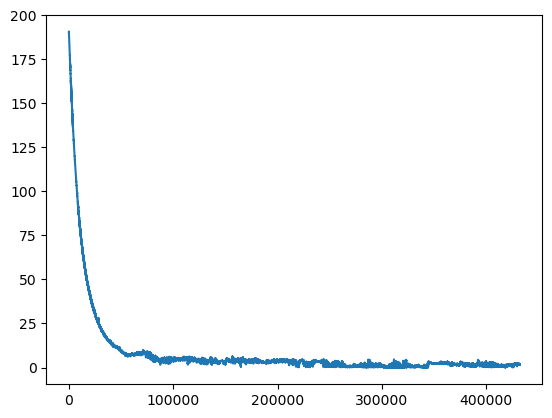

In [70]:
df['BTOTAL'].plot()

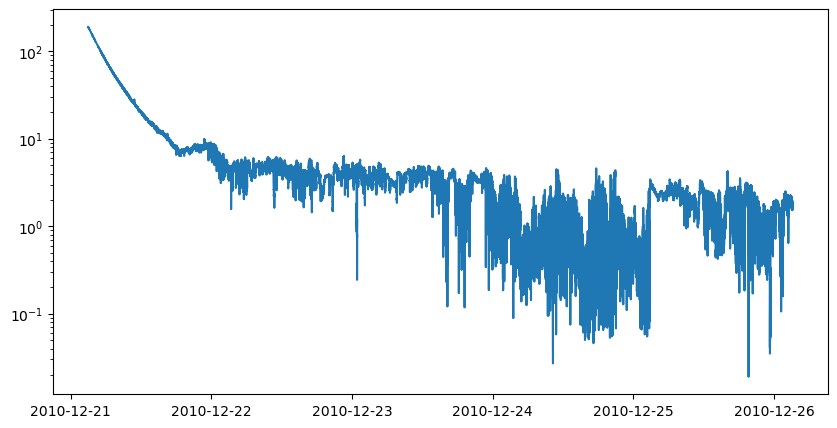

In [72]:
fig,ax=plt.subplots(figsize=(10,5))
ax.plot(df['TIME'],df['BTOTAL'])
ax.set_yscale('log')

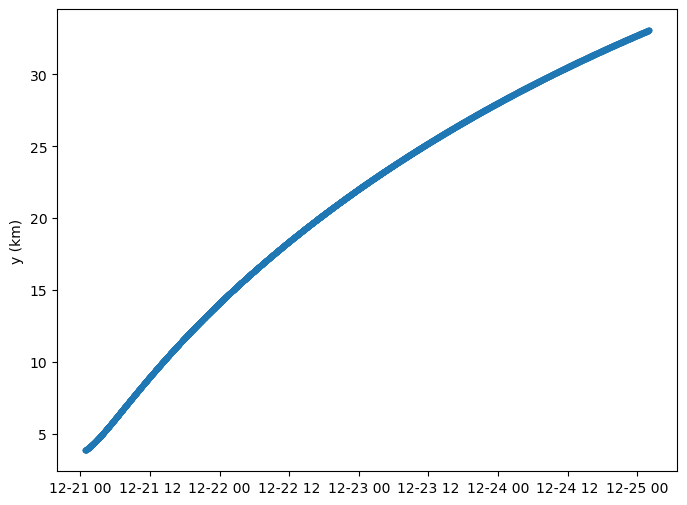

In [79]:
start_utc = pd.to_datetime("2010-12-21 00:50:00", utc=True)
end_utc  = pd.to_datetime("2010-12-25 02:00:00", utc=True)
n_points = 1000

#select the data in the given time range
mask = (cassini_location['utc'] >= start_utc) & (cassini_location['utc'] <= end_utc)
cassini_subset = cassini_location.loc[mask]

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(cassini_subset['utc'], np.sqrt(cassini_subset['x_km']**2+cassini_subset['y_km']**2 + cassini_subset['z_km']**2)/60268, marker='o', linestyle='-', markersize=3)
ax.set_ylabel("y (km)")
# ax.set_title("Cassini Location in x-y plane from 2010-12-21 to 2010-12-22")
plt.show()